Language: **English (default)** | [Polski](examples.ipynb)

# Lecture 12 -- experiment: autoencoders, VAE, and latent space

Companion material to [`lecture.en.md`](lecture.en.md). Four experiments:
(A) autoencoder (AE) on KMNIST, effect of latent dimension; (B) VAE --
architecture, training, evolution of the reconstruction and KL loss; (C)
2D latent space -- reconstruction vs. interpolation vs. generation; (D)
effect of the KL weight (beta sweep). Also: verifying the KL formula and
the reparameterization trick against PyTorch, and a demonstration of the
mean-vs-sum KL reduction bug's effect.

Everything runs on CPU. Dataset: KMNIST (already registered in
`data/registry.yml`, used in lab 6 -- here again, in a lecture role).

In [1]:
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.datasets as tvd
import torchvision.transforms as T

torch.manual_seed(0)
torch.set_num_threads(4)
device = torch.device("cpu")
print(f"Using device: {device}")

notebook_t0 = time.time()

Using device: cpu


## 0. A small numerical example (manual AE)

The same example as in `lecture.en.md` -- a linear encoder/decoder,
$d_x=4$, $d_e=2$, no training, just verifying the reconstruction-loss
formula.

In [2]:
x = torch.tensor([1.0, 0.5, -0.5, 0.0])
W_enc = torch.tensor([[1.0, 0.0, 0.0, 0.0], [0.0, 1.0, 1.0, 0.0]])
e = W_enc @ x
W_dec = W_enc.T
x_hat = W_dec @ e
loss = ((x - x_hat) ** 2).sum()
print(f"x     = {x.tolist()}")
print(f"e     = {e.tolist()}")
print(f"x_hat = {x_hat.tolist()}")
print(f"L_AE  = {loss.item():.4f}  (expected: 0.5)")
assert abs(loss.item() - 0.5) < 1e-6

x     = [1.0, 0.5, -0.5, 0.0]
e     = [1.0, 0.0]
x_hat = [1.0, 0.0, 0.0, 0.0]
L_AE  = 0.5000  (expected: 0.5)


## A. Autoencoder (AE) on KMNIST -- effect of latent dimension

We load KMNIST (a training/test subset for speed on CPU), define a small
AE (MLP), and train it for three latent-dimension values $d_e \in \{2, 8, 32\}$,
3 random seeds each, to check whether the effect is
stable, not accidental.

In [3]:
_REPO_ROOT = next(
    (
        parent
        for parent in (Path.cwd(), *Path.cwd().parents)
        if (parent / "pyproject.toml").is_file()
    ),
    Path.cwd(),
)
DATA_CACHE_DIR = (
    Path(os.environ.get("DEEP_LEARNING_DATA_CACHE", _REPO_ROOT / "data_cache"))
    .expanduser()
    .resolve()
)
t0 = time.time()
train_full = tvd.KMNIST(root=DATA_CACHE_DIR, train=True, download=True, transform=T.ToTensor())
test_full = tvd.KMNIST(root=DATA_CACHE_DIR, train=False, download=True, transform=T.ToTensor())
print(f"KMNIST load time: {time.time() - t0:.2f}s")

N_TRAIN, N_TEST = 8000, 2000
train_X = torch.stack([train_full[i][0] for i in range(N_TRAIN)])
test_X = torch.stack([test_full[i][0] for i in range(N_TEST)])
test_y = torch.tensor([test_full[i][1] for i in range(N_TEST)])
D_IN = 28 * 28
print(f"train_X: {train_X.shape}, test_X: {test_X.shape}")

KMNIST load time: 0.03s
train_X: torch.Size([8000, 1, 28, 28]), test_X: torch.Size([2000, 1, 28, 28])


In [4]:
class AE(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(D_IN, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Linear(64, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, D_IN),
            nn.Sigmoid(),
        )

    def forward(self, x):
        e = self.encoder(x)
        return self.decoder(e).view(-1, 1, 28, 28), e


def train_ae(latent_dim, epochs=20, batch_size=128, lr=1e-3, seed=0):
    torch.manual_seed(seed)
    model = AE(latent_dim)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    n = train_X.shape[0]
    t0 = time.time()
    for _ in range(epochs):
        perm = torch.randperm(n)
        for i in range(0, n, batch_size):
            idx = perm[i : i + batch_size]
            batch = train_X[idx]
            opt.zero_grad()
            x_hat, _ = model(batch)
            loss = F.mse_loss(x_hat, batch)
            loss.backward()
            opt.step()
    total_time = time.time() - t0
    model.eval()
    with torch.no_grad():
        test_mse = F.mse_loss(model(test_X)[0], test_X).item()
    return model, total_time, test_mse

In [5]:
ae_results = {}
for latent_dim in [2, 8, 32]:
    mses, times = [], []
    for seed in [0, 1, 2]:
        m, t, mse = train_ae(latent_dim, epochs=20, seed=seed)
        mses.append(mse)
        times.append(t)
        if seed == 0:
            ae_results[latent_dim] = m
    print(
        f"d_e={latent_dim}: train_time~{sum(times) / len(times):.2f}s, "
        f"test MSE across seeds = {[round(x, 5) for x in mses]}"
    )

d_e=2: train_time~1.37s, test MSE across seeds = [0.08306, 0.08445, 0.08304]


d_e=8: train_time~1.33s, test MSE across seeds = [0.06305, 0.06269, 0.0624]


d_e=32: train_time~1.32s, test MSE across seeds = [0.05132, 0.05261, 0.05055]


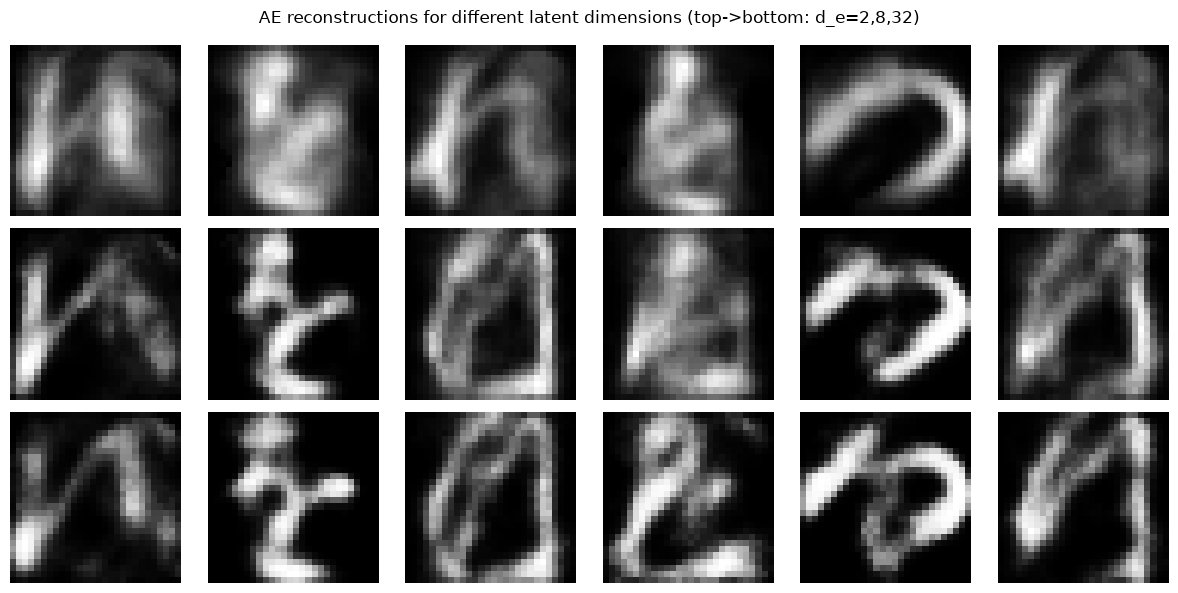

In [6]:
fig, axes = plt.subplots(3, 6, figsize=(12, 6))
n_show = 6
for row, latent_dim in enumerate([2, 8, 32]):
    model = ae_results[latent_dim]
    model.eval()
    with torch.no_grad():
        x_hat, _ = model(test_X[:n_show])
    for col in range(n_show):
        ax = axes[row, col]
        if row == 0:
            orig_ax = ax
        ax.imshow(x_hat[col, 0].numpy(), cmap="gray")
        ax.axis("off")
        if col == 0:
            ax.set_ylabel(f"d_e={latent_dim}")
fig.suptitle("AE reconstructions for different latent dimensions (top->bottom: d_e=2,8,32)")
plt.tight_layout()
plt.show()

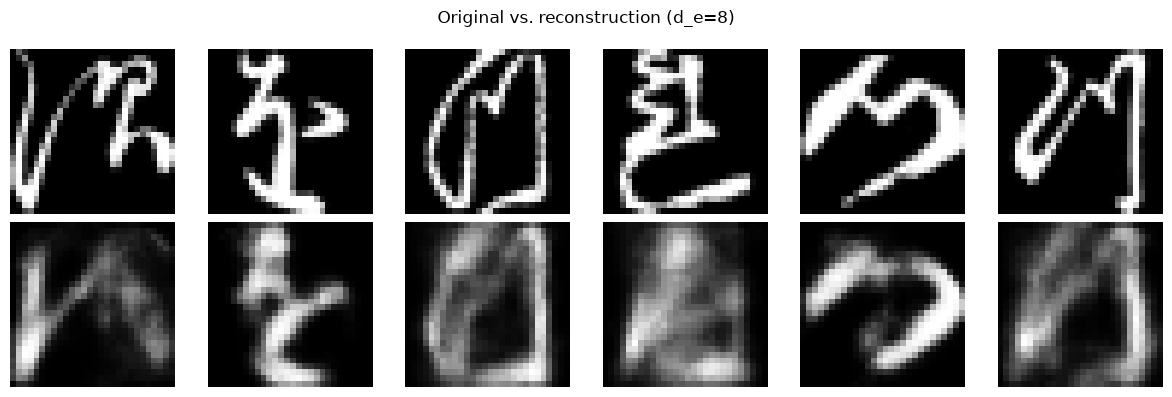

In [7]:
fig, axes = plt.subplots(2, 6, figsize=(12, 4))
with torch.no_grad():
    x_hat, _ = ae_results[8](test_X[:6])
for col in range(6):
    axes[0, col].imshow(test_X[col, 0].numpy(), cmap="gray")
    axes[0, col].axis("off")
    axes[1, col].imshow(x_hat[col, 0].numpy(), cmap="gray")
    axes[1, col].axis("off")
axes[0, 0].set_ylabel("original")
axes[1, 0].set_ylabel("recon (d_e=8)")
fig.suptitle("Original vs. reconstruction (d_e=8)")
plt.tight_layout()
plt.show()

**Observation.** The test MSE decreases with larger $d_e$ in this
specific, finite experiment (visible in the printed numbers above) -- we
treat this as a measured observation of this run, not a universal
guarantee (see `lecture.en.md`, "Undercomplete vs. overcomplete" section).

## Verification: overcomplete vs. undercomplete AE on synthetic data

Before moving to VAE, a brief verification of the theorem from
`lecture.en.md`: an overcomplete AE on full-rank data can learn a trivial
identity mapping, an undercomplete one cannot.

In [8]:
torch.manual_seed(0)
d_toy = 8
X_toy = torch.randn(500, d_toy)  # full rank, no low-dimensional structure


class ToyAE(nn.Module):
    def __init__(self, d, latent):
        super().__init__()
        self.enc = nn.Linear(d, latent)
        self.dec = nn.Linear(latent, d)

    def forward(self, x):
        return self.dec(torch.relu(self.enc(x)))


def train_toy(latent, epochs=500):
    torch.manual_seed(0)
    model = ToyAE(d_toy, latent)
    opt = torch.optim.Adam(model.parameters(), lr=1e-2)
    for _ in range(epochs):
        opt.zero_grad()
        loss = F.mse_loss(model(X_toy), X_toy)
        loss.backward()
        opt.step()
    return loss.item()


mse_overcomplete = train_toy(latent=32)
mse_undercomplete = train_toy(latent=2)
print(f"overcomplete AE (latent=32 > d={d_toy}) final MSE: {mse_overcomplete:.6f}")
print(f"undercomplete AE (latent=2 < d={d_toy}) final MSE: {mse_undercomplete:.6f}")
assert mse_overcomplete < 1e-3
assert mse_undercomplete > 0.3

overcomplete AE (latent=32 > d=8) final MSE: 0.000056
undercomplete AE (latent=2 < d=8) final MSE: 0.692368


## B. VAE -- architecture, training, loss evolution

The encoder returns `mu`/`logvar` (not a ready-made sample),
`reparameterize` implements the reparameterization trick, `vae_loss`
computes the reconstruction (BCE-with-logits, summed over pixels) and KL
(summed over latent dimensions), both divided by the batch size (an
explicit convention, consistent with `lecture.en.md`).

In [9]:
class VAE(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.latent_dim = latent_dim
        self.enc_shared = nn.Sequential(
            nn.Flatten(),
            nn.Linear(D_IN, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU(),
        )
        self.fc_mu = nn.Linear(64, latent_dim)
        self.fc_logvar = nn.Linear(64, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, D_IN),
        )

    def encode(self, x):
        h = self.enc_shared(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        eps = torch.randn_like(mu)
        return mu + torch.exp(0.5 * logvar) * eps

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar, z


def vae_loss(x_logits, x, mu, logvar, beta=1.0):
    recon = F.binary_cross_entropy_with_logits(x_logits, x, reduction="sum") / x.shape[0]
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / x.shape[0]
    return recon, kl, recon + beta * kl


def train_vae(latent_dim, epochs=20, batch_size=128, lr=1e-3, beta=1.0, seed=0):
    torch.manual_seed(seed)
    model = VAE(latent_dim)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    n = train_X.shape[0]
    t0 = time.time()
    history = {"recon": [], "kl": []}
    for _ in range(epochs):
        perm = torch.randperm(n)
        epoch_recon, epoch_kl = 0.0, 0.0
        for i in range(0, n, batch_size):
            idx = perm[i : i + batch_size]
            batch = train_X[idx]
            opt.zero_grad()
            x_logits, mu, logvar, z = model(batch)
            recon, kl, loss = vae_loss(x_logits, batch, mu, logvar, beta=beta)
            loss.backward()
            opt.step()
            epoch_recon += recon.item() * len(idx)
            epoch_kl += kl.item() * len(idx)
        history["recon"].append(epoch_recon / n)
        history["kl"].append(epoch_kl / n)
    return model, time.time() - t0, history

In [10]:
vae16, t16, h16 = train_vae(16, epochs=20)
print(f"VAE d_z=16, train_time={t16:.2f}s")
print(f"recon: {[round(x, 1) for x in h16['recon']]}")
print(f"KL:    {[round(x, 2) for x in h16['kl']]}")

VAE d_z=16, train_time=1.71s
recon: [384.0, 320.0, 306.6, 298.2, 289.0, 274.9, 263.8, 256.1, 249.6, 243.9, 239.7, 236.2, 233.4, 231.1, 228.9, 227.0, 225.4, 223.6, 221.8, 220.2]
KL:    [1.56, 4.71, 5.96, 7.23, 8.35, 10.74, 12.12, 12.97, 13.87, 14.62, 15.05, 15.32, 15.48, 15.66, 15.82, 15.93, 16.12, 16.4, 16.61, 16.77]


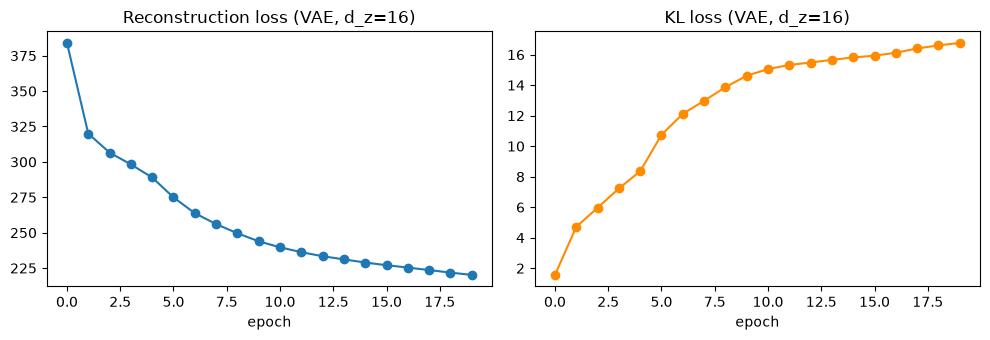

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(h16["recon"], marker="o")
axes[0].set_title("Reconstruction loss (VAE, d_z=16)")
axes[0].set_xlabel("epoch")
axes[1].plot(h16["kl"], marker="o", color="darkorange")
axes[1].set_title("KL loss (VAE, d_z=16)")
axes[1].set_xlabel("epoch")
plt.tight_layout()
plt.show()

**Observation.** The reconstruction loss steadily decreases over
training, while KL **grows** -- the model "discovers" that it can improve
reconstruction if it allows itself a larger departure from the prior.
Both components evolve together, not independently.

## Verification: the KL formula vs. `torch.distributions`, the reparameterization trick, and the gradient

Exactly the same numerical example as in `lecture.en.md`.

In [12]:
from torch.distributions import Normal, kl_divergence

mu = torch.tensor([0.5, -0.3])
logvar = torch.tensor([-0.2, 0.4])
sigma = torch.exp(0.5 * logvar)

kl_manual = 0.5 * (sigma.pow(2) + mu.pow(2) - 1 - logvar)
kl_torch = kl_divergence(Normal(mu, sigma), Normal(torch.zeros(2), torch.ones(2)))
print(f"KL (manual formula):      {kl_manual.tolist()}")
print(f"KL (torch.distributions): {kl_torch.tolist()}")
assert torch.allclose(kl_manual, kl_torch, atol=1e-6)
print(f"KL sum: {kl_manual.sum().item():.4f}")

# non-negativity on 1000 random examples
torch.manual_seed(1)
mu_rand = torch.randn(1000, 2)
logvar_rand = torch.randn(1000, 2)
kl_rand = 0.5 * (logvar_rand.exp() + mu_rand.pow(2) - 1 - logvar_rand)
print(f"min per-dim KL over 1000 random examples: {kl_rand.min().item():.6f} (expected >= 0)")
assert kl_rand.min().item() >= -1e-5

KL (manual formula):      [0.13436540961265564, 0.09091238677501678]
KL (torch.distributions): [0.13436540961265564, 0.09091237187385559]
KL sum: 0.2253
min per-dim KL over 1000 random examples: 0.000391 (expected >= 0)


In [13]:
mu_g = torch.tensor([0.5, -0.3], requires_grad=True)
logvar_g = torch.tensor([-0.2, 0.4], requires_grad=True)
eps_fixed = torch.tensor([1.0, -0.5])

z = mu_g + torch.exp(0.5 * logvar_g) * eps_fixed
print(f"z = {z.tolist()}  (expected: [1.4048, -0.9107])")

loss = (z**2).sum()
loss.backward()
print(f"mu.grad     = {mu_g.grad.tolist()}  (expected: 2*z = {(2 * z.detach()).tolist()})")
print(f"logvar.grad = {logvar_g.grad.tolist()}")

expected_logvar_grad = 2 * z.detach() * eps_fixed * 0.5 * torch.exp(0.5 * logvar_g.detach())
print(f"expected logvar.grad: {expected_logvar_grad.tolist()}")
assert torch.allclose(mu_g.grad, 2 * z.detach(), atol=1e-4)
assert torch.allclose(logvar_g.grad, expected_logvar_grad, atol=1e-4)
assert torch.isfinite(mu_g.grad).all() and torch.isfinite(logvar_g.grad).all()

z = [1.4048373699188232, -0.9107013940811157]  (expected: [1.4048, -0.9107])
mu.grad     = [2.8096747398376465, -1.8214027881622314]  (expected: 2*z = [2.8096747398376465, -1.8214027881622314])
logvar.grad = [1.2711493968963623, 0.5561665892601013]
expected logvar.grad: [1.2711493968963623, 0.5561665892601013]


## C. 2D latent space -- reconstruction, interpolation, generation

We train a VAE with $d_z=2$ (only for easy visualization -- see the
warning in `lecture.en.md` about what 2D does **not** show about
higher-dimensional models).

In [14]:
vae2d, t2d, h2d = train_vae(2, epochs=25)
print(
    f"VAE d_z=2, train_time={t2d:.2f}s, "
    f"final recon={h2d['recon'][-1]:.2f}, final KL={h2d['kl'][-1]:.3f}"
)

vae2d.eval()
with torch.no_grad():
    mu_test, logvar_test = vae2d.encode(test_X)

VAE d_z=2, train_time=2.04s, final recon=269.82, final KL=5.772


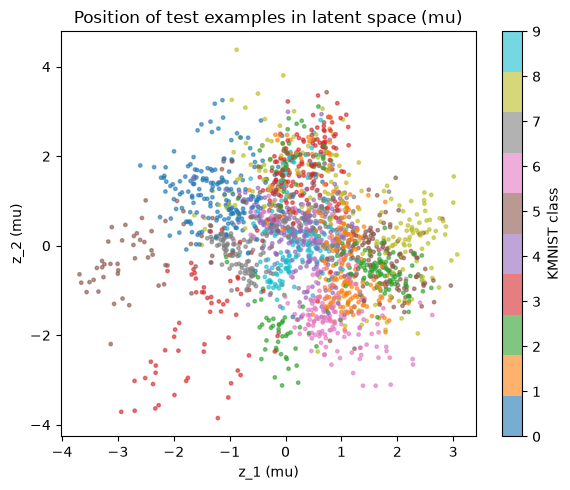

In [15]:
plt.figure(figsize=(6, 5))
scatter = plt.scatter(mu_test[:, 0], mu_test[:, 1], c=test_y, cmap="tab10", s=6, alpha=0.6)
plt.colorbar(scatter, label="KMNIST class")
plt.xlabel("z_1 (mu)")
plt.ylabel("z_2 (mu)")
plt.title("Position of test examples in latent space (mu)")
plt.tight_layout()
plt.show()

interpolating between test[0] (class 2) and test[1] (class 9)


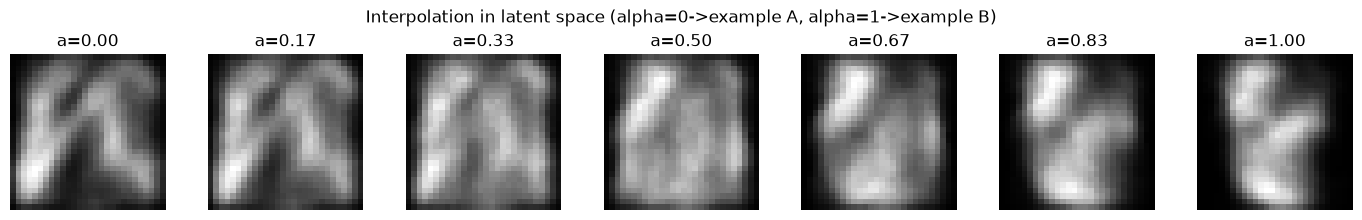

mean pixel difference between interpolation steps: [0.0293, 0.0402, 0.0536, 0.0566, 0.0501, 0.0411]


In [16]:
with torch.no_grad():
    idx_a, idx_b = 0, 1
    while test_y[idx_a].item() == test_y[idx_b].item():
        idx_b += 1
    mu_a, mu_b = mu_test[idx_a], mu_test[idx_b]
    print(
        f"interpolating between test[{idx_a}] (class {test_y[idx_a].item()}) "
        f"and test[{idx_b}] (class {test_y[idx_b].item()})"
    )

    alphas = torch.linspace(0, 1, 7)
    interp_imgs = [
        torch.sigmoid(vae2d.decode(((1 - a) * mu_a + a * mu_b).unsqueeze(0))) for a in alphas
    ]

    fig, axes = plt.subplots(1, 7, figsize=(14, 2.2))
    for i, img in enumerate(interp_imgs):
        axes[i].imshow(img[0, 0].numpy(), cmap="gray")
        axes[i].set_title(f"a={alphas[i]:.2f}")
        axes[i].axis("off")
    fig.suptitle("Interpolation in latent space (alpha=0->example A, alpha=1->example B)")
    plt.tight_layout()
    plt.show()

    diffs = [
        (interp_imgs[i + 1] - interp_imgs[i]).abs().mean().item()
        for i in range(len(interp_imgs) - 1)
    ]
    print(f"mean pixel difference between interpolation steps: {[round(d, 4) for d in diffs]}")

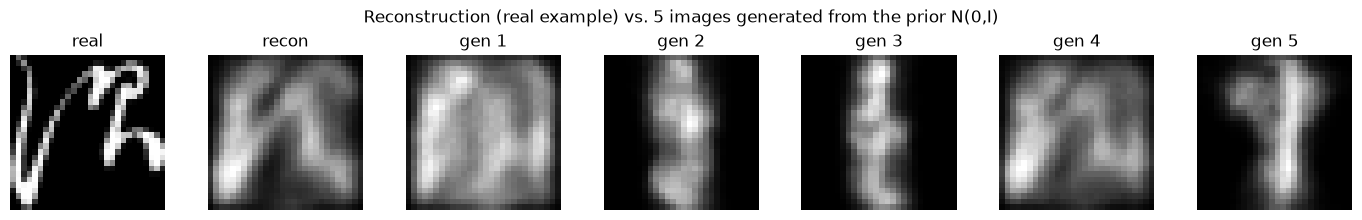

mean pixel difference: reconstruction vs. generation from prior = 0.0881


In [17]:
with torch.no_grad():
    real_img = test_X[idx_a : idx_a + 1]
    recon_img = torch.sigmoid(vae2d.decode(mu_test[idx_a : idx_a + 1]))

    torch.manual_seed(7)
    prior_samples = torch.randn(5, 2)
    gen_imgs = torch.sigmoid(vae2d.decode(prior_samples))

    diff_recon_gen = (recon_img - gen_imgs[0:1]).abs().mean().item()

fig, axes = plt.subplots(1, 7, figsize=(14, 2.2))
axes[0].imshow(real_img[0, 0].numpy(), cmap="gray")
axes[0].set_title("real")
axes[0].axis("off")
axes[1].imshow(recon_img[0, 0].numpy(), cmap="gray")
axes[1].set_title("recon")
axes[1].axis("off")
for i in range(5):
    axes[2 + i].imshow(gen_imgs[i, 0].numpy(), cmap="gray")
    axes[2 + i].set_title(f"gen {i + 1}")
    axes[2 + i].axis("off")
fig.suptitle("Reconstruction (real example) vs. 5 images generated from the prior N(0,I)")
plt.tight_layout()
plt.show()

print(f"mean pixel difference: reconstruction vs. generation from prior = {diff_recon_gen:.4f}")

**Observation.** Pixel differences between consecutive interpolation
steps are stable, with no sudden jumps (a locally smooth transition), and
reconstruction and generation from the prior give noticeably different
images -- these are three different operations, not three names for the
same activity. Reminder: this is a model with an **exceptionally small**,
2-dimensional latent space, chosen purely for visualization -- the
results do not represent a higher-dimensional model (e.g. Experiment B,
$d_z=16$).

## D. Effect of the KL weight (beta sweep)

We train a VAE with $d_z=8$ for several values of $\beta$ and compare the
final reconstruction and KL loss.

In [18]:
beta_results = {}
for beta in [0.0, 0.1, 1.0, 5.0, 25.0]:
    model, t, h = train_vae(8, epochs=20, beta=beta)
    beta_results[beta] = (model, h)
    print(f"beta={beta}: recon={h['recon'][-1]:.2f}, KL={h['kl'][-1]:.3f}")

beta=0.0: recon=213.45, KL=207.101


beta=0.1: recon=214.94, KL=33.704


beta=1.0: recon=223.19, KL=15.067


beta=5.0: recon=256.85, KL=5.607


beta=25.0: recon=321.86, KL=0.670


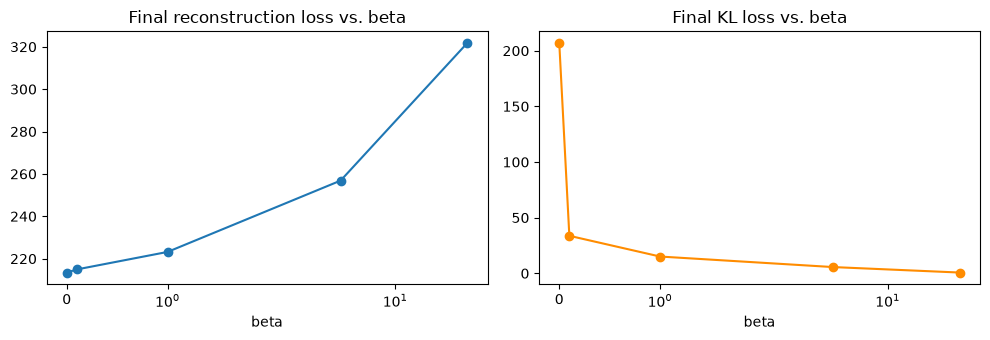

In [19]:
betas = list(beta_results.keys())
final_recon = [beta_results[b][1]["recon"][-1] for b in betas]
final_kl = [beta_results[b][1]["kl"][-1] for b in betas]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(betas, final_recon, marker="o")
axes[0].set_xscale("symlog")
axes[0].set_xlabel("beta")
axes[0].set_title("Final reconstruction loss vs. beta")
axes[1].plot(betas, final_kl, marker="o", color="darkorange")
axes[1].set_xscale("symlog")
axes[1].set_xlabel("beta")
axes[1].set_title("Final KL loss vs. beta")
plt.tight_layout()
plt.show()

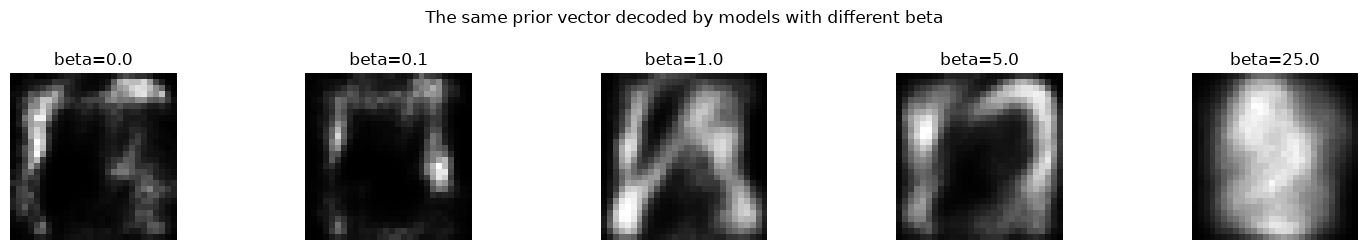

In [20]:
fig, axes = plt.subplots(1, len(betas), figsize=(3 * len(betas), 2.5))
torch.manual_seed(0)
z_fixed = torch.randn(1, 8)
for i, b in enumerate(betas):
    model = beta_results[b][0]
    model.eval()
    with torch.no_grad():
        img = torch.sigmoid(model.decode(z_fixed))
    axes[i].imshow(img[0, 0].numpy(), cmap="gray")
    axes[i].set_title(f"beta={b}")
    axes[i].axis("off")
fig.suptitle("The same prior vector decoded by models with different beta")
plt.tight_layout()
plt.show()

**Observation.** $\beta=0$ gives a very high KL (practically no
regularization of the latent space -- behavior close to a plain AE);
$\beta=25$ strongly reduces KL, but at the cost of clearly worse
reconstruction. Both phenomena ("too weak" and "too strong"
regularization) actually occurred in this experiment -- no need to
correct the narrative.

## Verification: the buggy KL reduction (mean vs. sum)

We show the measured effect of swapping `sum` for `mean` over latent
dimensions in the KL term (for $d_z=8$) -- exactly the example from
`lecture.en.md`.

In [21]:
def vae_loss_buggy_mean_kl(x_logits, x, mu, logvar):
    recon = F.binary_cross_entropy_with_logits(x_logits, x, reduction="sum") / x.shape[0]
    kl_wrong = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())  # BUG: mean, not sum
    return recon, kl_wrong, recon + kl_wrong


def train_vae_buggy(latent_dim, epochs=15, batch_size=128, lr=1e-3, seed=7):
    torch.manual_seed(seed)
    model = VAE(latent_dim)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    n = train_X.shape[0]
    history = {"recon": [], "kl": []}
    for _ in range(epochs):
        perm = torch.randperm(n)
        er, ek = 0.0, 0.0
        for i in range(0, n, batch_size):
            idx = perm[i : i + batch_size]
            batch = train_X[idx]
            opt.zero_grad()
            x_logits, mu, logvar, z = model(batch)
            recon, kl, loss = vae_loss_buggy_mean_kl(x_logits, batch, mu, logvar)
            loss.backward()
            opt.step()
            er += recon.item() * len(idx)
            ek += kl.item() * len(idx)
        history["recon"].append(er / n)
        history["kl"].append(ek / n)
    return history


_, _, h_correct = train_vae(8, epochs=15, beta=1.0, seed=7)
h_buggy = train_vae_buggy(8, epochs=15, seed=7)

print(
    f"correct reduction (sum over latent dimensions): "
    f"final recon={h_correct['recon'][-1]:.2f}, final KL={h_correct['kl'][-1]:.3f}"
)
print(
    f"buggy reduction (mean over latent dimensions):  "
    f"final recon={h_buggy['recon'][-1]:.2f}, final KL (as computed)={h_buggy['kl'][-1]:.3f}"
)
print(
    "-> the buggy version has a lower effective KL weight (about 8x smaller for d_z=8), "
    "giving a deceptively 'better' reconstruction with weaker latent-space regularization"
)

correct reduction (sum over latent dimensions): final recon=230.71, final KL=14.409
buggy reduction (mean over latent dimensions):  final recon=221.57, final KL (as computed)=3.761
-> the buggy version has a lower effective KL weight (about 8x smaller for d_z=8), giving a deceptively 'better' reconstruction with weaker latent-space regularization


In [22]:
print(f"\ntotal notebook execution time: {time.time() - notebook_t0:.1f}s")


total notebook execution time: 27.3s
